# SURFMATCH × PA6 activity — threshold-specific orientations + structural groups

This notebook generates **two plots for every orientation × plotted metric × temperature**:

1. **Standard plot**
   - one point colour;
   - no Top-rated highlighting;
   - overall Pearson, Spearman and Kendall correlations;
   - linear regression;
   - legend outside the plotting area;
   - protein labels are automatically displaced to reduce overlap.

2. **Structural-group plot**
   - points are coloured according to the structural clusters derived from the US-align dendrogram cut at **D = 0.50** (`distance = 1 − TM-score`);
   - the same global correlation/regression is retained;
   - within-group correlations are calculated only when a group contains at least `MIN_GROUP_CORR_N` matched enzymes;
   - groups with fewer enzymes are still plotted and shown in the legend.

The default analysis uses **threshold = 0.50**, but `TARGET_THRESHOLD` can be changed in the configuration cell.

For each method (**FORMULA** and **PEARSON**) the notebook automatically selects the orientations corresponding to:

- `global_score`
- `positive_total_area`
- `positive_max_area`
- `negative_total_area`
- `negative_max_area`

For **each of those orientations**, activity is correlated with:

- `global_score`
- `positive_total_area`
- `positive_max_area`
- `negative_total_area`
- `negative_max_area`

The title format is intentionally kept the same as in the previous notebook:

```text
CODE | orientation selected from METHOD orientation_metric, threshold=X
METHOD_plotted_metric_temperature
Pearson ... | Spearman ... | Kendall ...
Pearson log1p(activity) ...
```


## 1. Configuration

In [13]:
from pathlib import Path

# ============================================================
# INPUT FILES
# ============================================================
ACTIVITY_FILE = Path("/home/chiara/Desktop/COMENZE/Surfmatch_pipeline/SURFMATCH_VS_ACTIVITY_NYLON/Bell_activity_40_50_degree.xlsx")
SURFMATCH_FILE = Path("/home/chiara/Desktop/COMENZE/Surfmatch_pipeline/SURFMATCH_VS_ACTIVITY_NYLON/rankings_all_proteins.txt")

# ============================================================
# MAIN ANALYSIS PARAMETERS
# ============================================================
# Change this value to rerun the same analysis at another threshold.
TARGET_THRESHOLD = 0.50

METHODS = ["formula", "pearson"]

ORIENTATION_METRICS = [
    "global_score",
    "positive_total_area",
    "positive_max_area",
    "negative_total_area",
    "negative_max_area",
]

PLOTTED_METRICS = [
    "global_score",
    "positive_total_area",
    "positive_max_area",
    "negative_total_area",
    "negative_max_area",
]

TEMPERATURES = ["40C", "50C"]

# Minimum number of matched enzymes required to calculate
# a within-structural-group correlation.
MIN_GROUP_CORR_N = 4

# ============================================================
# NAME MATCHING
# ============================================================
NORMALIZE_SURFMATCH_NAMES = True
SURFMATCH_NAME_SUFFIX = "_4rev_aligned"

# Bell UMGSP2 can be mapped to either available SURFMATCH structure.
# Change only this line if you want to use the other structure.
UMGSP2_STRUCTURE = "8WDW_UMGSP2"
# Alternative:
# UMGSP2_STRUCTURE = "9FZW_UMGSP2"

APPLY_NAME_ALIASES = True

# ============================================================
# OUTPUT
# ============================================================
OUTPUT_BASE_PATH = Path("/home/chiara/Desktop/COMENZE/Surfmatch_pipeline/SURFMATCH_VS_ACTIVITY_NYLON")
OUTPUT_FOLDER_NAME = "activity_vs_match_structural_groups_regression_colors_thr050"
OUTPUT_DIR = OUTPUT_BASE_PATH / OUTPUT_FOLDER_NAME

SAVE_PLOTS = True
SHOW_PLOTS = True
SAVE_PNG = True
SAVE_PDF = True

# Folder structure:
#
# OUTPUT_DIR/
# ├── 40C/
# │   ├── png/
# │   │   ├── standard/
# │   │   └── structural_groups/
# │   └── pdf/
# │       ├── standard/
# │       └── structural_groups/
# └── 50C/
#     └── ...
#
STRUCTURAL_PLOT_VARIANTS = [
    "global_only",
    "nylonases",
    "urethanases",
    "cutinases",
]

for temp in TEMPERATURES:
    for ext in ["png", "pdf"]:
        (OUTPUT_DIR / temp / ext / "standard").mkdir(
            parents=True, exist_ok=True
        )

        for variant in STRUCTURAL_PLOT_VARIANTS:
            (
                OUTPUT_DIR
                / temp
                / ext
                / "structural_groups"
                / variant
            ).mkdir(
                parents=True,
                exist_ok=True,
            )

# ============================================================
# PLOT STYLE
# ============================================================
FIGSIZE_STANDARD = (13.5, 8.5)
FIGSIZE_GROUPED = (15.0, 8.5)

FONT_SIZE = 14
TITLE_SIZE = 17
AXIS_LABEL_SIZE = 16
TICK_SIZE = 13
LEGEND_SIZE = 10
POINT_LABEL_SIZE = 9

POINT_SIZE = 58
POINT_ALPHA = 0.82

# Standard graph: one colour only.
STANDARD_POINT_COLOR = "#1f77b4"


# ============================================================
# STRUCTURAL GROUP COLORS
# ============================================================
# Main groups: deliberately high-contrast colours.
# Smaller / sparse groups: grey shades so they remain visible
# without competing visually with the three main groups.

STRUCTURAL_GROUP_COLORS = {
    # Main structural groups
    "SG1 NylC-like": "#2E7D32",                 # green
    "SG2 Amidase / urethane-like": "#7B1FA2",   # purple
    "SG3 Cutinase / PETase-like": "#F28E2B",    # orange

    # Smaller groups / isolated branches
    "SG4 MGS0156 / LipBC": "#4D4D4D",
    "SG5 Lipase-like": "#666666",
    "SG6 Trypsin / chymotrypsin": "#7F7F7F",
    "SG7 Papain / bromelain": "#969696",
    "SG8 lipAN isolated": "#AAAAAA",
    "SG9 lipCR isolated": "#BDBDBD",
    "SG10 Subtilisin isolated": "#D0D0D0",
}

# Fallback colour if a future structural group is added but not
# explicitly listed above.
STRUCTURAL_GROUP_FALLBACK_COLOR = "#BDBDBD"

# Figure appearance: always white background and black text.
FIGURE_BACKGROUND = "white"
AXES_BACKGROUND = "white"
TEXT_COLOR = "black"

# Label displacement.
REPEL_LABELS = True
REPEL_ITERATIONS = 140
REPEL_PADDING = 1.08
DRAW_LABEL_CONNECTORS = True

# Use shorter labels such as NylCa instead of 3AXG_NylCa.
SHORTEN_DISPLAY_NAMES = True

REPORT_LOG1P_PEARSON = True

print("Target threshold:", TARGET_THRESHOLD)
print("Output:", OUTPUT_DIR)


Target threshold: 0.5
Output: /home/chiara/Desktop/COMENZE/Surfmatch_pipeline/SURFMATCH_VS_ACTIVITY_NYLON/activity_vs_match_structural_groups_regression_colors_thr050


## 2. Imports and general utilities

In [14]:
import re
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.lines import Line2D
from scipy.stats import pearsonr, spearmanr, kendalltau

plt.rcParams.update({
    "font.size": FONT_SIZE,
    "axes.titlesize": TITLE_SIZE,
    "axes.labelsize": AXIS_LABEL_SIZE,
    "xtick.labelsize": TICK_SIZE,
    "ytick.labelsize": TICK_SIZE,

    # Force presentation-safe black text on white background.
    "text.color": TEXT_COLOR,
    "axes.labelcolor": TEXT_COLOR,
    "axes.edgecolor": TEXT_COLOR,
    "axes.titlecolor": TEXT_COLOR,
    "xtick.color": TEXT_COLOR,
    "ytick.color": TEXT_COLOR,
    "figure.facecolor": FIGURE_BACKGROUND,
    "axes.facecolor": AXES_BACKGROUND,
    "savefig.facecolor": FIGURE_BACKGROUND,
    "legend.labelcolor": TEXT_COLOR,
})



def p_fmt(p):
    if pd.isna(p):
        return "NA"
    if p < 0.001:
        return f"{p:.2e}"
    return f"{p:.3g}"


def format_threshold(value):
    if pd.isna(value):
        return "global"
    return f"{float(value):.2f}"


def parse_activity(value):
    """Convert Bell activity cells to a numeric value."""
    if pd.isna(value):
        return np.nan

    if isinstance(value, (int, float, np.integer, np.floating)):
        return float(value)

    text = str(value).strip().replace(",", ".")

    # Preserve the previous notebook behaviour for simple ranges.
    # Example: "0-1" -> 0.5
    range_match = re.fullmatch(
        r"\s*([-+]?\d*\.?\d+)\s*[-–]\s*([-+]?\d*\.?\d+)\s*",
        text,
    )
    if range_match:
        a = float(range_match.group(1))
        b = float(range_match.group(2))
        return (a + b) / 2.0

    number_match = re.search(r"[-+]?\d*\.?\d+(?:[eE][-+]?\d+)?", text)
    if number_match:
        return float(number_match.group(0))

    return np.nan


def shorten_name(name):
    if not SHORTEN_DISPLAY_NAMES:
        return str(name)

    text = str(name)

    # Remove a leading PDB-like identifier only for display.
    text = re.sub(r"^[0-9][A-Za-z0-9]{3}_", "", text)

    # Cosmetic suffixes.
    text = text.replace("_AF3", "")
    text = text.replace("_CYS26", "")

    return text


## 3. Activity data and robust enzyme-name matching

In [15]:
def build_name_aliases():
    aliases = {
        # NylC-like
        "nc_NylC": "nc_NylC_AF3",
        "nc_NylC_AF3": "nc_NylC_AF3",
        "ph_NylC": "ph_NylC_AF3",
        "ph_NylC_AF3": "ph_NylC_AF3",
        "tt_NylC": "tt_NylC_AF3",
        "tt_NylC_AF3": "tt_NylC_AF3",
        "NylCa": "3AXG_NylCa",
        "3AXG_NylCa": "3AXG_NylCa",
        "NylCp2": "5XYG_NylCp2",
        "5XYG_nylcp2": "5XYG_NylCp2",
        "5XYG_NylCp2": "5XYG_NylCp2",
        "NylCp2_TS": "5Y0M_NylCp2_TS",
        "5Y0M_nylcp2_TS": "5Y0M_NylCp2_TS",
        "5Y0M_NylCp2_TS": "5Y0M_NylCp2_TS",
        "NylCk": "NylCk_AF3",
        "NylCk_AF3": "NylCk_AF3",

        # NylB / amidase-like
        "NylB": "1WYB_NylB",
        "1WYC_NylB": "1WYB_NylB",
        "1WYB_NylB": "1WYB_NylB",
        "GatA": "GatA_AF3",
        "GatA_AF3": "GatA_AF3",
        "MsmegA": "MsmegA_AF3",
        "MsmegA_AF3": "MsmegA_AF3",
        "NfpolyA": "NfpolyA_AF3",
        "NfpolyA_AF3": "NfpolyA_AF3",
        "Ooh": "Ooh_AF3",
        "Ooh_AF3": "Ooh_AF3",
        "ReU": "ReU_AF3",
        "ReU_AF3": "ReU_AF3",
        "TtA": "TtA_AF3",
        "TtA_AF3": "TtA_AF3",
        "UMGSP1": "8S7Z_UMGSP1",
        "UMGSP1_AF3": "8S7Z_UMGSP1",
        "8S7Z_UMGSP1": "8S7Z_UMGSP1",
        "UMGSP2": UMGSP2_STRUCTURE,
        "8WDW_UMGSP2": "8WDW_UMGSP2",
        "9FZW_UMGSP2": "9FZW_UMGSP2",
        "UMGSP3": "9FVF_UMGSP3",
        "UMGSP3_AF3": "9FVF_UMGSP3",
        "9FVF_UMGSP3": "9FVF_UMGSP3",

        # Cutinase/PETase-like
        "3GBS_aoc": "3GBS_AoC",
        "3GBS_AoC": "3GBS_AoC",
        "Cut190": "7CEF_Cut190",
        "Cut190*": "7CEF_Cut190",
        "7CEF_Cut190": "7CEF_Cut190",
        "FsC": "1CEX_FsC",
        "1CEX_cutfv": "1CEX_FsC",
        "1CEX_FsC": "1CEX_FsC",
        "HiC": "4OYY_HiC",
        "4OYY_hic": "4OYY_HiC",
        "4OYY_HiC": "4OYY_HiC",
        "HotPETase": "7QVH_HotPETase",
        "7QVH_HotPETase": "7QVH_HotPETase",
        "LCC_ICCG": "8OTA_LCC_ICCG",
        "LCC-ICCG": "8OTA_LCC_ICCG",
        "8OTA_LCC_ICCG": "8OTA_LCC_ICCG",
        "ThcCut2": "5LUJ_ThcCut2",
        "Thccut2_AF3": "5LUJ_ThcCut2",
        "5LUJ_ThcCut2": "5LUJ_ThcCut2",
        "ThcCut1": "5LUI_ThcCut1",
        "Thccut1_AF3": "5LUI_ThcCut1",
        "5LUI_ThcCut1": "5LUI_ThcCut1",
        "Tfcut2": "4CG1_Tfcut2",
        "4CG1_Tfcut2": "4CG1_Tfcut2",

        # Other hydrolases / proteases
        "chymotrypsin": "4CHA_chymotrypsin",
        "α-Chymotrypsin": "4CHA_chymotrypsin",
        "4CHA_chymotrypsin": "4CHA_chymotrypsin",
        "Papain": "1PPN_Papain",
        "1PPN_pap": "1PPN_Papain",
        "1PPN_Papain": "1PPN_Papain",
        "Trypsin": "1TPO_Trypsin",
        "1TPO_tryp": "1TPO_Trypsin",
        "1TPO_Trypsin": "1TPO_Trypsin",
        "Subtilisin": "1SBC_Subtilisin",
        "1SBC_sub": "1SBC_Subtilisin",
        "1SBC_Subtilisin": "1SBC_Subtilisin",
        "5D8M_MGS0156": "5D8M_MGS0156",
    }
    return aliases


NAME_ALIASES = build_name_aliases()


def load_activity_sheet(sheet_name):
    df = pd.read_excel(ACTIVITY_FILE, sheet_name=sheet_name)

    enzyme_col = "Enzima"

    activity_candidates = [
        c for c in df.columns
        if "Netto" in str(c) and "µM" in str(c)
    ]
    if not activity_candidates:
        raise ValueError(
            f"No background-corrected activity column found in {sheet_name!r}."
        )

    activity_col = activity_candidates[0]

    out = df[[enzyme_col, activity_col]].copy()
    out.columns = ["protein_activity_raw", "activity_uM"]

    out["protein"] = (
        out["protein_activity_raw"]
        .astype(str)
        .str.strip()
    )

    if APPLY_NAME_ALIASES:
        out["protein"] = out["protein"].replace(NAME_ALIASES)

    out["activity_uM"] = out["activity_uM"].apply(parse_activity)

    return out.dropna(subset=["activity_uM"])


activity_by_temp = {
    "40C": load_activity_sheet("40 degree"),
    "50C": load_activity_sheet("50 degree"),
}

for temp, df in activity_by_temp.items():
    print(temp, "activity rows:", len(df))


40C activity rows: 40
50C activity rows: 40


## 4. Parse all SURFMATCH ranking tables

In [16]:
SURFMATCH_COLUMNS = [
    "position",
    "rank",
    "protein",
    "group",
    "nylon_id",
    "roi_radius",
    "global_score",
    "positive_max_area",
    "positive_total_area",
    "negative_max_area",
    "negative_total_area",
    "rotation_angle",
    "positive_contribution",
    "negative_magnitude",
    "roi_pixels",
]

NUMERIC_COLUMNS = [
    "position",
    "rank",
    "roi_radius",
    "global_score",
    "positive_max_area",
    "positive_total_area",
    "negative_max_area",
    "negative_total_area",
    "rotation_angle",
    "positive_contribution",
    "negative_magnitude",
    "roi_pixels",
]


def parse_table_header(line):
    # Example:
    # TABLE 031/154 , METHOD=FORMULA ,
    # RANKING=positive_total_area , THRESHOLD=0.50
    m = re.search(
        r"TABLE\s+(\d+)/\d+\s*,\s*"
        r"METHOD=([A-Za-z]+)\s*,\s*"
        r"RANKING=([A-Za-z0-9_]+)\s*,\s*"
        r"THRESHOLD=(.+)$",
        line.strip(),
    )

    if not m:
        raise ValueError(f"Could not parse table header: {line}")

    code = m.group(1).zfill(3)
    method = m.group(2).lower()
    ranking = m.group(3)
    threshold_text = m.group(4).strip()

    if threshold_text.upper().startswith("N/A"):
        threshold = np.nan
    else:
        threshold = float(threshold_text)

    return {
        "table_code": code,
        "method": method,
        "orientation_metric": ranking,
        "threshold": threshold,
    }


def parse_all_surfmatch_tables(path):
    lines = Path(path).read_text(encoding="utf-8").splitlines()

    all_tables = []
    metadata_rows = []

    i = 0
    while i < len(lines):
        if not lines[i].startswith("TABLE "):
            i += 1
            continue

        meta = parse_table_header(lines[i])

        # Expected format:
        # TABLE...
        # SCOPE...
        # blank
        # header
        header_idx = i + 3

        if header_idx >= len(lines):
            break

        header = lines[header_idx].split()
        if header != SURFMATCH_COLUMNS:
            raise ValueError(
                f"Unexpected SURFMATCH columns in table {meta['table_code']}.\n"
                f"Found: {header}"
            )

        rows = []
        j = header_idx + 1

        while j < len(lines) and not lines[j].startswith("TABLE "):
            line = lines[j].strip()
            if line:
                parts = line.split()
                if len(parts) != len(SURFMATCH_COLUMNS):
                    raise ValueError(
                        f"Table {meta['table_code']}: expected "
                        f"{len(SURFMATCH_COLUMNS)} columns, got "
                        f"{len(parts)} at line:\n{lines[j]}"
                    )
                rows.append(parts)
            j += 1

        df = pd.DataFrame(rows, columns=SURFMATCH_COLUMNS)

        for col in NUMERIC_COLUMNS:
            df[col] = pd.to_numeric(df[col], errors="coerce")

        df["protein_raw"] = df["protein"].astype(str)

        if NORMALIZE_SURFMATCH_NAMES:
            df["protein"] = df["protein_raw"].str.replace(
                re.escape(SURFMATCH_NAME_SUFFIX),
                "",
                regex=True,
            )

        for key, value in meta.items():
            df[key] = value

        all_tables.append(df)
        metadata_rows.append(meta)

        i = j

    if not all_tables:
        raise ValueError("No SURFMATCH tables were parsed.")

    return (
        pd.concat(all_tables, ignore_index=True),
        pd.DataFrame(metadata_rows).drop_duplicates(),
    )


surf_all, table_index = parse_all_surfmatch_tables(SURFMATCH_FILE)

print("Parsed tables:", len(table_index))
print("Rows:", len(surf_all))


Parsed tables: 154
Rows: 7238


## 5. Structural groups from the US-align dendrogram

The grouping below follows the **D = 0.50 structural cut** used in the circular US-align dendrogram.

The open/closed conformations present in the SURFMATCH dataset are assigned to the same structural group as the corresponding enzyme.

The mapping is explicit and editable so that it can be updated if the structural clustering is rerun.


In [17]:
# ============================================================
# STRUCTURAL GROUPS
# ============================================================

STRUCTURAL_GROUP_MEMBERS = {
    "SG1 NylC-like": [
        "TvgC_AF3",
        "9DYS_Nyl50",
        "ph_NylC_AF3",
        "tt_NylC_AF3",
        "nc_NylC_AF3",
        "NylCk_AF3",
        "pam1_AF3",
        "3AXG_NylCa",
        "5Y0M_NylCp2_TS",
        "5XYG_NylCp2",
    ],

    "SG2 Amidase / urethane-like": [
        "1WYB_NylB",
        "8S7Z_UMGSP1",
        "9FVF_UMGSP3",
        "9FZW_UMGSP2",
        "8WDW_UMGSP2",
        "GatA_AF3",
        "ReU_AF3",
        "MsmegA_AF3",
        "NfpolyA_AF3",
        "Ooh_AF3",
        "TtA_AF3",
    ],

    "SG3 Cutinase / PETase-like": [
        "8OTA_LCC_ICCG",
        "4EB0_LCC",
        "5LUJ_ThcCut2",
        "4CG1_Tfcut2",
        "5LUI_ThcCut1",
        "7CEF_Cut190",
        "7QVH_HotPETase",
        "1CEX_FsC",
        "1CUS_fsc",
        "1FFA_FsC_N84A",
        "4OYY_HiC",
        "3GBS_AoC",
    ],

    "SG4 MGS0156 / LipBC": [
        "5D8M_MGS0156",
        "1OIL_LipBC_open",
    ],

    "SG5 Lipase-like": [
        "1DTE_lipTL_open",
        "1DT5_lipTL_closed",
        "4TGL_lipRM_open",
        "3TGL_LipRM_closed",
    ],

    "SG6 Trypsin / chymotrypsin": [
        "1TPO_Trypsin",
        "4CHA_chymotrypsin",
    ],

    "SG7 Papain / bromelain": [
        "1PPN_Papain",
        "6YCE_Bromelain_CYS26",
    ],

    # Structurally isolated branches in the D=0.50 dendrogram.
    "SG8 lipAN isolated": [
        "lipAN_AF3",
    ],

    "SG9 lipCR isolated": [
        "1CRL_lipCr_open",
        "1TRH_lipCR_closed",
    ],

    "SG10 Subtilisin isolated": [
        "1SBC_Subtilisin",
    ],
}


PROTEIN_TO_STRUCTURAL_GROUP = {}

for group_name, members in STRUCTURAL_GROUP_MEMBERS.items():
    for protein in members:
        if protein in PROTEIN_TO_STRUCTURAL_GROUP:
            raise ValueError(
                f"{protein} appears in more than one structural group."
            )
        PROTEIN_TO_STRUCTURAL_GROUP[protein] = group_name


# Validate coverage against all proteins in SURFMATCH.
surf_proteins = sorted(surf_all["protein"].unique())

unassigned = [
    p for p in surf_proteins
    if p not in PROTEIN_TO_STRUCTURAL_GROUP
]

if unassigned:
    warnings.warn(
        "Some SURFMATCH proteins are not assigned to a structural group:\n"
        + "\n".join(unassigned)
    )
else:
    print("All SURFMATCH proteins have a structural-group assignment.")

print("\nStructural groups:")
for group_name, members in STRUCTURAL_GROUP_MEMBERS.items():
    print(f"  {group_name}: {len(members)} structure(s)")


All SURFMATCH proteins have a structural-group assignment.

Structural groups:
  SG1 NylC-like: 10 structure(s)
  SG2 Amidase / urethane-like: 11 structure(s)
  SG3 Cutinase / PETase-like: 12 structure(s)
  SG4 MGS0156 / LipBC: 2 structure(s)
  SG5 Lipase-like: 4 structure(s)
  SG6 Trypsin / chymotrypsin: 2 structure(s)
  SG7 Papain / bromelain: 2 structure(s)
  SG8 lipAN isolated: 1 structure(s)
  SG9 lipCR isolated: 2 structure(s)
  SG10 Subtilisin isolated: 1 structure(s)


## 6. Automatically select the requested orientation tables

In [18]:
def select_orientation_tables(
    table_index,
    threshold=TARGET_THRESHOLD,
    methods=METHODS,
    orientation_metrics=ORIENTATION_METRICS,
):
    selected = []

    for method in methods:
        for metric in orientation_metrics:

            subset = table_index[
                table_index["method"].eq(method)
                & table_index["orientation_metric"].eq(metric)
            ].copy()

            if metric == "global_score":
                subset = subset[subset["threshold"].isna()]
            else:
                subset = subset[
                    np.isclose(
                        subset["threshold"].astype(float),
                        float(threshold),
                        atol=1e-9,
                    )
                ]

            if len(subset) != 1:
                raise ValueError(
                    f"Expected exactly one table for method={method}, "
                    f"metric={metric}, threshold={threshold}; "
                    f"found {len(subset)}."
                )

            selected.append(subset.iloc[0])

    return pd.DataFrame(selected).reset_index(drop=True)


selected_orientations = select_orientation_tables(table_index)

display(
    selected_orientations[
        [
            "table_code",
            "method",
            "orientation_metric",
            "threshold",
        ]
    ]
)

ORIENTATION_TABLE_CODES = (
    selected_orientations["table_code"]
    .astype(str)
    .tolist()
)

print("Selected codes:", ", ".join(ORIENTATION_TABLE_CODES))
print(
    "Expected plot combinations:",
    len(ORIENTATION_TABLE_CODES)
    * len(PLOTTED_METRICS)
    * len(TEMPERATURES),
)
print(
    "Expected figure files (standard + grouped):",
    len(ORIENTATION_TABLE_CODES)
    * len(PLOTTED_METRICS)
    * len(TEMPERATURES)
    * 2,
)


,table_code,method,orientation_metric,threshold
0,001,formula,global_score,NaN
1,031,formula,positive_total_area,0.5
2,012,formula,positive_max_area,0.5
3,069,formula,negative_total_area,0.5
4,050,formula,negative_max_area,0.5
5,078,pearson,global_score,NaN
6,108,pearson,positive_total_area,0.5
7,089,pearson,positive_max_area,0.5
8,146,pearson,negative_total_area,0.5
9,127,pearson,negative_max_area,0.5


Selected codes: 001, 031, 012, 069, 050, 078, 108, 089, 146, 127
Expected plot combinations: 100
Expected figure files (standard + grouped): 200


## 7. Correlation statistics and label-repulsion helper

In [19]:
def correlation_stats(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    if len(x) < 3:
        return {
            "n": len(x),
            "pearson_r": np.nan,
            "pearson_p": np.nan,
            "spearman_r": np.nan,
            "spearman_p": np.nan,
            "kendall_r": np.nan,
            "kendall_p": np.nan,
            "log_pearson_r": np.nan,
            "log_pearson_p": np.nan,
            "slope": np.nan,
            "intercept": np.nan,
            "r2": np.nan,
            "rmse": np.nan,
        }

    pearson_r, pearson_p = pearsonr(x, y)
    spearman_r, spearman_p = spearmanr(x, y)
    kendall_r, kendall_p = kendalltau(x, y)

    log_y = np.log1p(y)
    log_pearson_r, log_pearson_p = pearsonr(x, log_y)

    slope, intercept = np.polyfit(x, y, 1)
    y_hat = slope * x + intercept

    ss_res = np.sum((y - y_hat) ** 2)
    ss_tot = np.sum((y - np.mean(y)) ** 2)

    r2 = (
        1 - ss_res / ss_tot
        if ss_tot > 0
        else np.nan
    )

    rmse = np.sqrt(np.mean((y - y_hat) ** 2))

    return {
        "n": len(x),
        "pearson_r": pearson_r,
        "pearson_p": pearson_p,
        "spearman_r": spearman_r,
        "spearman_p": spearman_p,
        "kendall_r": kendall_r,
        "kendall_p": kendall_p,
        "log_pearson_r": log_pearson_r,
        "log_pearson_p": log_pearson_p,
        "slope": slope,
        "intercept": intercept,
        "r2": r2,
        "rmse": rmse,
    }


def repel_point_labels(
    ax,
    x,
    y,
    labels,
    fontsize=POINT_LABEL_SIZE,
    max_iter=REPEL_ITERATIONS,
    padding=REPEL_PADDING,
    draw_connectors=DRAW_LABEL_CONNECTORS,
):
    """
    Lightweight label-repulsion routine using only Matplotlib.

    Labels are initially placed close to their point, then iteratively
    displaced in axes coordinates when bounding boxes overlap.
    Thin connector lines are added when a label moves sufficiently far.
    """
    if len(labels) == 0:
        return []

    fig = ax.figure
    fig.canvas.draw()

    xy_data = np.column_stack([
        np.asarray(x, dtype=float),
        np.asarray(y, dtype=float),
    ])

    xy_disp = ax.transData.transform(xy_data)
    xy_axes = ax.transAxes.inverted().transform(xy_disp)

    texts = []

    for i, ((px, py), label) in enumerate(zip(xy_axes, labels)):
        # Alternating initial offsets reduce exact overlaps before iteration.
        dx = 0.008 if i % 2 == 0 else -0.008
        dy = 0.010 + (i % 3) * 0.005

        tx = np.clip(px + dx, 0.01, 0.99)
        ty = np.clip(py + dy, 0.01, 0.99)

        text_obj = ax.text(
            tx,
            ty,
            str(label),
            transform=ax.transAxes,
            fontsize=fontsize,
            ha="left" if dx >= 0 else "right",
            va="bottom",
            zorder=8,
        )
        texts.append(text_obj)

    fig.canvas.draw()

    renderer = fig.canvas.get_renderer()

    for _ in range(max_iter):
        moved = False

        bboxes = [
            t.get_window_extent(renderer=renderer).expanded(
                padding,
                padding,
            )
            for t in texts
        ]

        for i in range(len(texts)):
            for j in range(i + 1, len(texts)):
                b1 = bboxes[i]
                b2 = bboxes[j]

                if not b1.overlaps(b2):
                    continue

                moved = True

                c1x = (b1.x0 + b1.x1) / 2
                c1y = (b1.y0 + b1.y1) / 2
                c2x = (b2.x0 + b2.x1) / 2
                c2y = (b2.y0 + b2.y1) / 2

                overlap_x = min(b1.x1, b2.x1) - max(b1.x0, b2.x0)
                overlap_y = min(b1.y1, b2.y1) - max(b1.y0, b2.y0)

                pos_i = np.array(texts[i].get_position(), dtype=float)
                pos_j = np.array(texts[j].get_position(), dtype=float)

                # Prefer vertical separation, with a smaller horizontal shift.
                y_shift_axes = (max(overlap_y, 2.0) / ax.bbox.height) * 0.58
                x_shift_axes = (max(overlap_x, 2.0) / ax.bbox.width) * 0.18

                if c1y <= c2y:
                    pos_i[1] -= y_shift_axes
                    pos_j[1] += y_shift_axes
                else:
                    pos_i[1] += y_shift_axes
                    pos_j[1] -= y_shift_axes

                if c1x <= c2x:
                    pos_i[0] -= x_shift_axes
                    pos_j[0] += x_shift_axes
                else:
                    pos_i[0] += x_shift_axes
                    pos_j[0] -= x_shift_axes

                pos_i = np.clip(pos_i, [0.01, 0.01], [0.99, 0.99])
                pos_j = np.clip(pos_j, [0.01, 0.01], [0.99, 0.99])

                texts[i].set_position(pos_i)
                texts[j].set_position(pos_j)

        if not moved:
            break

        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()

    if draw_connectors:
        for (px, py), text_obj in zip(xy_axes, texts):
            tx, ty = text_obj.get_position()

            distance = np.hypot(tx - px, ty - py)

            if distance > 0.022:
                ax.annotate(
                    "",
                    xy=(px, py),
                    xycoords=ax.transAxes,
                    xytext=(tx, ty),
                    textcoords=ax.transAxes,
                    arrowprops=dict(
                        arrowstyle="-",
                        linewidth=0.5,
                        color="0.55",
                        alpha=0.75,
                    ),
                    zorder=4,
                )

    return texts


## 8. Titles, matching and plotting functions

In [20]:
def make_title(meta, metric_to_plot, temp, stats):
    code = meta["table_code"]
    method = meta["method"].upper()
    orientation_metric = meta["orientation_metric"]
    threshold = format_threshold(meta["threshold"])

    if threshold == "global":
        line1 = (
            f"{code} | orientation selected from "
            f"{method} {orientation_metric}"
        )
    else:
        line1 = (
            f"{code} | orientation selected from "
            f"{method} {orientation_metric}, "
            f"threshold={threshold}"
        )

    line2 = f"{method}_{metric_to_plot}_{temp}"

    stat_line = (
        f"Pearson r={stats['pearson_r']:.3f} "
        f"(p={p_fmt(stats['pearson_p'])}) | "
        f"Spearman ρ={stats['spearman_r']:.3f} "
        f"(p={p_fmt(stats['spearman_p'])}) | "
        f"Kendall τ={stats['kendall_r']:.3f} "
        f"(p={p_fmt(stats['kendall_p'])})"
    )

    if REPORT_LOG1P_PEARSON:
        stat_line += (
            f"\nPearson log1p(activity) "
            f"r={stats['log_pearson_r']:.3f} "
            f"(p={p_fmt(stats['log_pearson_p'])})"
        )

    return line1 + "\n" + line2 + "\n" + stat_line


def automatic_x_label(metric):
    if metric == "global_score":
        return "SURFMATCH global score"
    return f"SURFMATCH score_{metric}"


def get_merged_data(temp, orientation_code, metric_to_plot):
    orientation_code = str(orientation_code).zfill(3)

    table = surf_all[
        surf_all["table_code"].eq(orientation_code)
    ].copy()

    if table.empty:
        raise ValueError(
            f"No SURFMATCH data for table {orientation_code}."
        )

    if metric_to_plot not in table.columns:
        raise ValueError(
            f"Metric {metric_to_plot!r} does not exist."
        )

    meta = table.iloc[0].to_dict()

    activity = activity_by_temp[temp].copy()

    merged = activity.merge(
        table,
        on="protein",
        how="inner",
        validate="one_to_one",
    ).dropna(
        subset=[metric_to_plot, "activity_uM"]
    ).copy()

    merged["structural_group"] = (
        merged["protein"]
        .map(PROTEIN_TO_STRUCTURAL_GROUP)
        .fillna("Unassigned")
    )

    merged["display_name"] = (
        merged["protein"]
        .apply(shorten_name)
    )

    return merged, meta


def add_global_regression(ax, x, stats):
    if pd.isna(stats["slope"]):
        return

    x_line = np.linspace(
        float(np.min(x)),
        float(np.max(x)),
        200,
    )

    y_line = (
        stats["slope"] * x_line
        + stats["intercept"]
    )

    ax.plot(
        x_line,
        y_line,
        linestyle="--",
        linewidth=2.0,
        color="black",
        label="Global linear regression",
        zorder=1,
    )


def add_stats_box(ax, stats):
    ax.text(
        0.02,
        0.98,
        (
            f"n = {stats['n']}\n"
            f"R² = {stats['r2']:.3f}\n"
            f"RMSE = {stats['rmse']:.2f} µM"
        ),
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=11,
        bbox=dict(
            boxstyle="round,pad=0.35",
            facecolor="white",
            edgecolor="0.7",
            alpha=0.92,
        ),
        zorder=10,
    )


def save_plot(fig, temp, kind, stem, variant=None):
    if not SAVE_PLOTS:
        return

    safe_stem = re.sub(
        r"[^A-Za-z0-9_.-]+",
        "_",
        stem,
    )

    if kind == "structural_groups":
        if variant is None:
            variant = "global_only"

        png_dir = (
            OUTPUT_DIR
            / temp
            / "png"
            / "structural_groups"
            / variant
        )
        pdf_dir = (
            OUTPUT_DIR
            / temp
            / "pdf"
            / "structural_groups"
            / variant
        )
    else:
        png_dir = OUTPUT_DIR / temp / "png" / kind
        pdf_dir = OUTPUT_DIR / temp / "pdf" / kind

    if SAVE_PNG:
        fig.savefig(
            png_dir / f"{safe_stem}.png",
            dpi=300,
            bbox_inches="tight",
            facecolor=FIGURE_BACKGROUND,
        )

    if SAVE_PDF:
        fig.savefig(
            pdf_dir / f"{safe_stem}.pdf",
            bbox_inches="tight",
            facecolor=FIGURE_BACKGROUND,
        )


def make_filename_stem(meta, metric_to_plot, temp):
    threshold = format_threshold(meta["threshold"])

    stem = (
        f"{meta['table_code']}_"
        f"orientation-from-{meta['orientation_metric']}_"
        f"{meta['method'].upper()}_"
        f"{metric_to_plot}_{temp}"
    )

    if threshold != "global":
        stem += f"_thr-{threshold}"

    return stem


## 9. Standard plot — one colour, no Top-rated information

In [21]:
def plot_standard(
    temp,
    orientation_code,
    metric_to_plot,
    show=True,
    save=True,
):
    merged, meta = get_merged_data(
        temp,
        orientation_code,
        metric_to_plot,
    )

    x = merged[metric_to_plot].to_numpy(dtype=float)
    y = merged["activity_uM"].to_numpy(dtype=float)

    stats = correlation_stats(x, y)

    fig, ax = plt.subplots(figsize=FIGSIZE_STANDARD, facecolor=FIGURE_BACKGROUND)
    ax.set_facecolor(AXES_BACKGROUND)

    ax.scatter(
        x,
        y,
        s=POINT_SIZE,
        alpha=POINT_ALPHA,
        color=STANDARD_POINT_COLOR,
        edgecolor="black",
        linewidth=0.5,
        label="Matched enzymes",
        zorder=3,
    )

    add_global_regression(ax, x, stats)

    ax.set_xlabel(automatic_x_label(metric_to_plot))
    ax.set_ylabel("PA6 activity (µM)")

    ax.set_title(
        make_title(meta, metric_to_plot, temp, stats),
        pad=18,
    )

    # Legend OUTSIDE the plotting region.
    ax.legend(
        loc="upper left",
        bbox_to_anchor=(1.02, 1.00),
        borderaxespad=0,
        frameon=True,
        fontsize=LEGEND_SIZE,
        facecolor="white",
        edgecolor="0.75",
    )

    # R² and RMSE are shown OUTSIDE the plotting area,
    # directly below the legend so they never cover data points.
    ax.text(
        1.02,
        0.78,
        (
            f"n = {stats['n']}\n"
            f"R² = {stats['r2']:.3f}\n"
            f"RMSE = {stats['rmse']:.2f} µM"
        ),
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=11,
        color=TEXT_COLOR,
        bbox=dict(
            boxstyle="round,pad=0.35",
            facecolor="white",
            edgecolor="0.75",
            alpha=1.0,
        ),
        clip_on=False,
        zorder=10,
    )

    # Reserve room on the right for legend and statistics.
    fig.subplots_adjust(right=0.78)

    if REPEL_LABELS:
        repel_point_labels(
            ax,
            x,
            y,
            merged["display_name"].tolist(),
        )

    stem = make_filename_stem(
        meta,
        metric_to_plot,
        temp,
    )

    if save:
        save_plot(
            fig,
            temp,
            "standard",
            stem + "_standard",
        )

    if show:
        plt.show()
    else:
        plt.close(fig)

    return {
        "plot_type": "standard",
        "orientation_code": meta["table_code"],
        "orientation_metric": meta["orientation_metric"],
        "method": meta["method"],
        "threshold": meta["threshold"],
        "metric_plotted": metric_to_plot,
        "temperature": temp,
        **stats,
    }


## 10. Structural-group plot — colours + within-group correlations

In [22]:
def compute_group_correlations(
    merged,
    metric_to_plot,
    min_n=MIN_GROUP_CORR_N,
):
    rows = []

    for group_name, group_df in (
        merged.groupby("structural_group", sort=True)
    ):
        n = len(group_df)

        row = {
            "structural_group": group_name,
            "group_n": n,
            "group_correlation_calculated": n >= min_n,
        }

        if n >= min_n:
            stats = correlation_stats(
                group_df[metric_to_plot],
                group_df["activity_uM"],
            )

            for key, value in stats.items():
                row[f"group_{key}"] = value

        rows.append(row)

    return pd.DataFrame(rows)



GROUP_REGRESSION_VARIANTS = {
    "nylonases": "SG1 NylC-like",
    "urethanases": "SG2 Amidase / urethane-like",
    "cutinases": "SG3 Cutinase / PETase-like",
}


def plot_structural_groups(
    temp,
    orientation_code,
    metric_to_plot,
    group_regression=None,
    show=True,
    save=True,
):
    """
    Structural-group plot.

    group_regression:
        None            -> global regression only
        "nylonases"     -> add SG1 NylC-like regression
        "urethanases"   -> add SG2 Amidase / urethane-like regression
        "cutinases"     -> add SG3 Cutinase / PETase-like regression

    The global points, colours, title and global correlation remain identical
    in all four versions. Only the additional coloured within-group regression
    line changes.
    """
    merged, meta = get_merged_data(
        temp,
        orientation_code,
        metric_to_plot,
    )

    x = merged[metric_to_plot].to_numpy(dtype=float)
    y = merged["activity_uM"].to_numpy(dtype=float)

    global_stats = correlation_stats(x, y)

    group_stats_df = compute_group_correlations(
        merged,
        metric_to_plot,
    )

    fig, ax = plt.subplots(
        figsize=FIGSIZE_GROUPED,
        facecolor=FIGURE_BACKGROUND,
    )
    ax.set_facecolor(AXES_BACKGROUND)

    present_groups = sorted(
        merged["structural_group"].unique()
    )

    # Fixed, presentation-stable colours.
    # The three main groups use high-contrast colours;
    # smaller groups use grey shades.
    group_colors = {
        group: STRUCTURAL_GROUP_COLORS.get(
            group,
            STRUCTURAL_GROUP_FALLBACK_COLOR,
        )
        for group in present_groups
    }

    legend_handles = []

    for group_name in present_groups:
        group_df = merged[
            merged["structural_group"].eq(group_name)
        ]

        color = group_colors[group_name]

        ax.scatter(
            group_df[metric_to_plot],
            group_df["activity_uM"],
            s=POINT_SIZE + 8,
            alpha=0.86,
            color=color,
            edgecolor="black",
            linewidth=0.55,
            zorder=3,
        )

        legend_handles.append(
            Line2D(
                [0],
                [0],
                marker="o",
                linestyle="None",
                markerfacecolor=color,
                markeredgecolor="black",
                markersize=8,
                label=f"{group_name} (n={len(group_df)})",
            )
        )

    # --------------------------------------------------------
    # Global regression — always identical in all versions
    # --------------------------------------------------------
    add_global_regression(ax, x, global_stats)

    legend_handles.append(
        Line2D(
            [0],
            [0],
            linestyle="--",
            color="black",
            linewidth=2,
            label="Global linear regression",
        )
    )

    selected_group_stats = None
    selected_group_name = None

    # --------------------------------------------------------
    # Optional within-group regression line
    # --------------------------------------------------------
    if group_regression is not None:
        if group_regression not in GROUP_REGRESSION_VARIANTS:
            raise ValueError(
                f"Unknown group_regression={group_regression!r}. "
                f"Choose from {list(GROUP_REGRESSION_VARIANTS)}."
            )

        selected_group_name = GROUP_REGRESSION_VARIANTS[group_regression]

        group_df = merged[
            merged["structural_group"].eq(selected_group_name)
        ].copy()

        if len(group_df) >= MIN_GROUP_CORR_N:
            selected_group_stats = correlation_stats(
                group_df[metric_to_plot],
                group_df["activity_uM"],
            )

            gx = group_df[metric_to_plot].to_numpy(dtype=float)

            gx_line = np.linspace(
                float(np.min(gx)),
                float(np.max(gx)),
                160,
            )

            gy_line = (
                selected_group_stats["slope"] * gx_line
                + selected_group_stats["intercept"]
            )

            group_color = group_colors[selected_group_name]

            ax.plot(
                gx_line,
                gy_line,
                linestyle="--",
                linewidth=2.6,
                color=group_color,
                zorder=2,
            )

            legend_handles.append(
                Line2D(
                    [0],
                    [0],
                    linestyle="--",
                    color=group_color,
                    linewidth=2.6,
                    label=(
                        f"{selected_group_name} regression "
                        f"(r={selected_group_stats['pearson_r']:.2f}, "
                        f"p={p_fmt(selected_group_stats['pearson_p'])})"
                    ),
                )
            )
        else:
            warnings.warn(
                f"{selected_group_name}: only {len(group_df)} matched enzymes; "
                f"group regression not calculated because "
                f"MIN_GROUP_CORR_N={MIN_GROUP_CORR_N}."
            )

    ax.set_xlabel(automatic_x_label(metric_to_plot))
    ax.set_ylabel("PA6 activity (µM)")

    # Title stays EXACTLY in the same format as before.
    ax.set_title(
        make_title(
            meta,
            metric_to_plot,
            temp,
            global_stats,
        ),
        pad=18,
    )

    # --------------------------------------------------------
    # LEGEND OUTSIDE
    # --------------------------------------------------------
    ax.legend(
        handles=legend_handles,
        title="Structural groups (D=0.50)",
        loc="upper left",
        bbox_to_anchor=(1.02, 1.00),
        borderaxespad=0,
        frameon=True,
        fontsize=LEGEND_SIZE,
        title_fontsize=LEGEND_SIZE + 1,
        facecolor="white",
        edgecolor="0.75",
    )

    # --------------------------------------------------------
    # Global n / R² / RMSE OUTSIDE, below legend
    # --------------------------------------------------------
    ax.text(
        1.02,
        0.43,
        (
            f"Global statistics\\n"
            f"n = {global_stats['n']}\\n"
            f"R² = {global_stats['r2']:.3f}\\n"
            f"RMSE = {global_stats['rmse']:.2f} µM"
        ),
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=10.5,
        color=TEXT_COLOR,
        bbox=dict(
            boxstyle="round,pad=0.38",
            facecolor="white",
            edgecolor="0.75",
            alpha=1.0,
        ),
        clip_on=False,
    )

    # --------------------------------------------------------
    # Within-group correlation summary OUTSIDE
    # --------------------------------------------------------
    correlation_lines = [
        f"Within-group correlations (n ≥ {MIN_GROUP_CORR_N})",
        "exploratory",
        "",
    ]

    for _, row in group_stats_df.iterrows():
        if not bool(row["group_correlation_calculated"]):
            continue

        correlation_lines.append(
            f"{row['structural_group']} "
            f"(n={int(row['group_n'])})"
        )

        correlation_lines.append(
            f"  Pearson r={row['group_pearson_r']:.2f} "
            f"(p={p_fmt(row['group_pearson_p'])})"
        )

        correlation_lines.append(
            f"  Spearman ρ={row['group_spearman_r']:.2f} "
            f"(p={p_fmt(row['group_spearman_p'])})"
        )

    ax.text(
        1.02,
        0.28,
        "\n".join(correlation_lines),
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=9.2,
        color=TEXT_COLOR,
        bbox=dict(
            boxstyle="round,pad=0.4",
            facecolor="white",
            edgecolor="0.75",
            alpha=1.0,
        ),
        clip_on=False,
    )

    # More room on the right because all annotations are external.
    fig.subplots_adjust(right=0.68)

    if REPEL_LABELS:
        repel_point_labels(
            ax,
            x,
            y,
            merged["display_name"].tolist(),
        )

    stem = make_filename_stem(
        meta,
        metric_to_plot,
        temp,
    )

    variant = (
        "global_only"
        if group_regression is None
        else group_regression
    )

    if save:
        save_plot(
            fig,
            temp,
            "structural_groups",
            stem + f"_structural_groups_{variant}",
            variant=variant,
        )

    if show:
        plt.show()
    else:
        plt.close(fig)

    global_result = {
        "plot_type": "structural_groups",
        "structural_variant": variant,
        "orientation_code": meta["table_code"],
        "orientation_metric": meta["orientation_metric"],
        "method": meta["method"],
        "threshold": meta["threshold"],
        "metric_plotted": metric_to_plot,
        "temperature": temp,
        **global_stats,
    }

    if selected_group_name is not None:
        global_result["highlighted_regression_group"] = selected_group_name

        if selected_group_stats is not None:
            global_result["highlighted_group_n"] = selected_group_stats["n"]
            global_result["highlighted_group_pearson_r"] = selected_group_stats["pearson_r"]
            global_result["highlighted_group_pearson_p"] = selected_group_stats["pearson_p"]
            global_result["highlighted_group_spearman_r"] = selected_group_stats["spearman_r"]
            global_result["highlighted_group_spearman_p"] = selected_group_stats["spearman_p"]

    # Attach identifying columns to the within-group table.
    group_stats_df = group_stats_df.copy()

    group_stats_df.insert(
        0,
        "structural_variant",
        variant,
    )
    group_stats_df.insert(
        0,
        "temperature",
        temp,
    )
    group_stats_df.insert(
        0,
        "metric_plotted",
        metric_to_plot,
    )
    group_stats_df.insert(
        0,
        "threshold",
        meta["threshold"],
    )
    group_stats_df.insert(
        0,
        "method",
        meta["method"],
    )
    group_stats_df.insert(
        0,
        "orientation_metric",
        meta["orientation_metric"],
    )
    group_stats_df.insert(
        0,
        "orientation_code",
        meta["table_code"],
    )

    return global_result, group_stats_df


## 11. Test one combination before generating everything

Test: 031 positive_total_area 40C


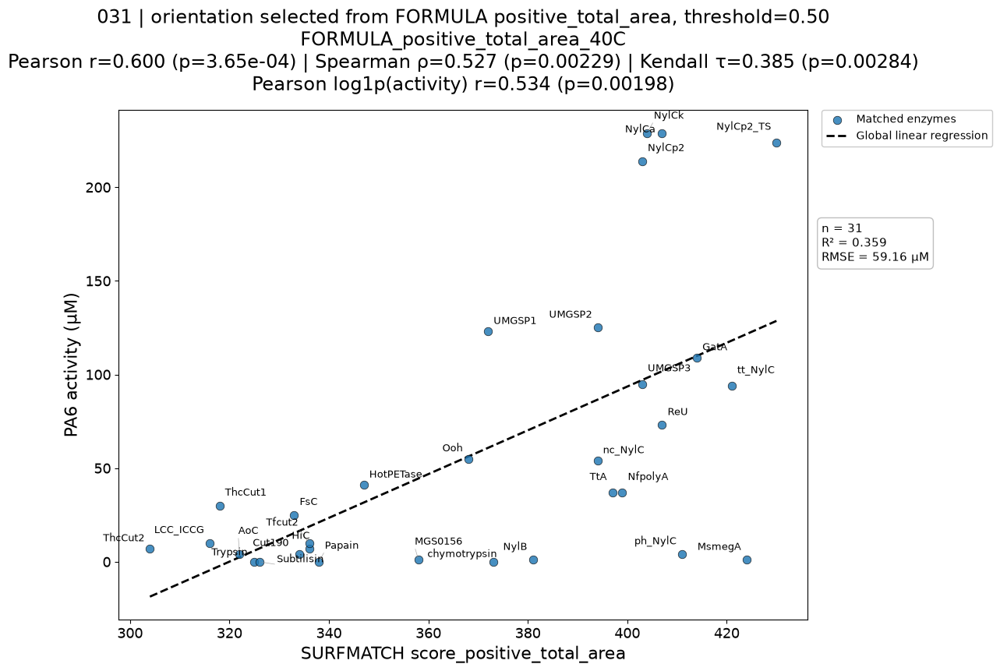

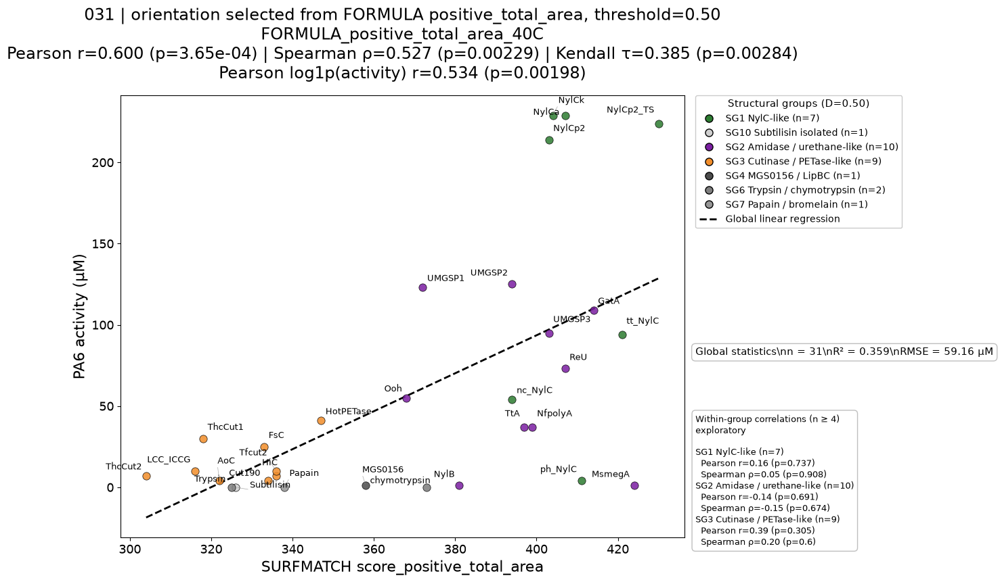

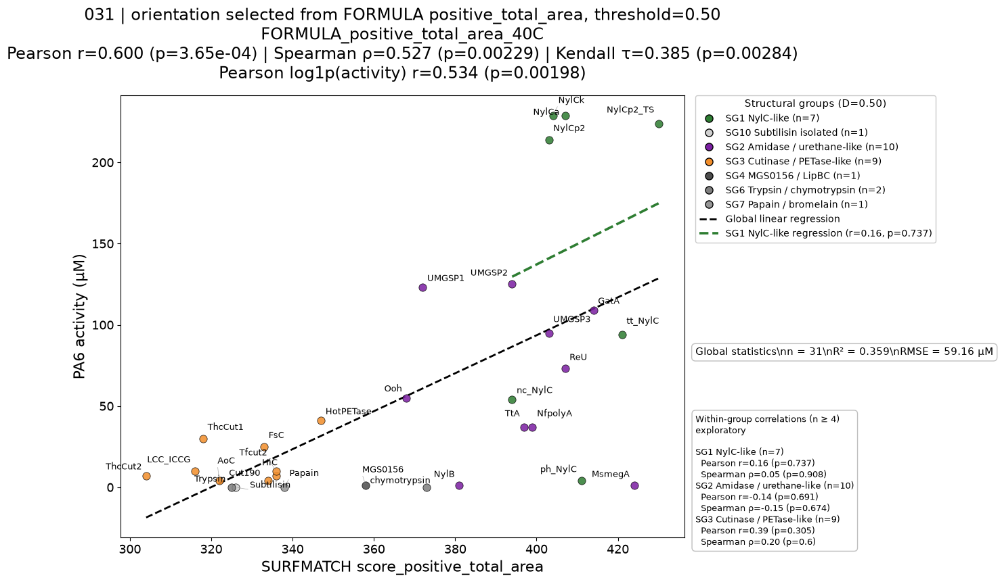

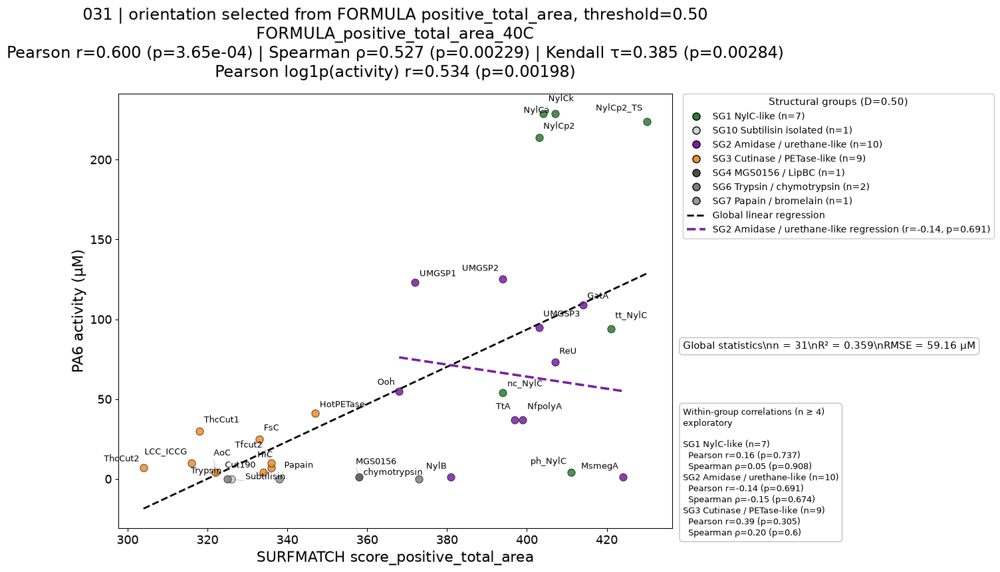

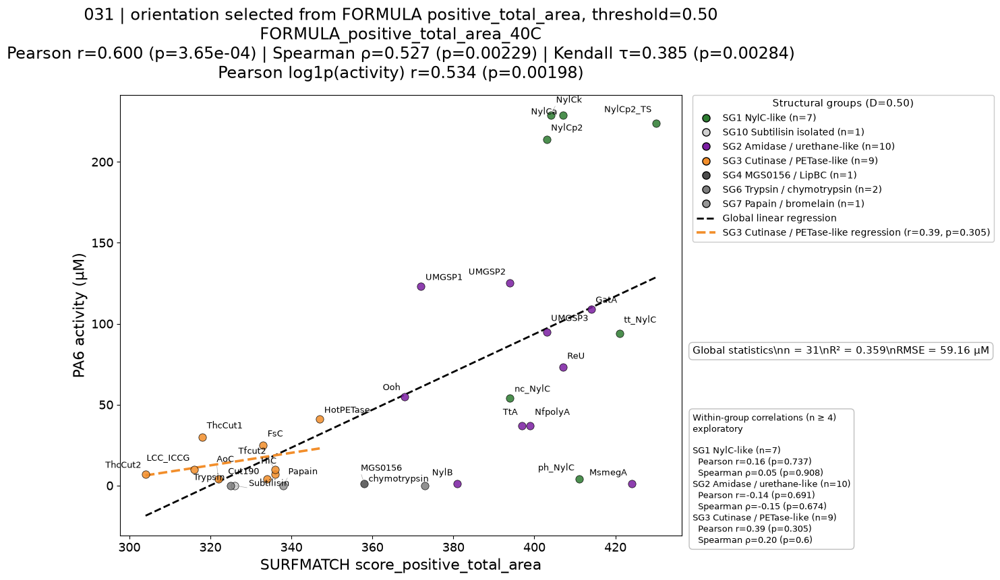

,orientation_code,orientation_metric,method,threshold,metric_plotted,temperature,structural_variant,structural_group,group_n,group_correlation_calculated,...,group_spearman_r,group_spearman_p,group_kendall_r,group_kendall_p,group_log_pearson_r,group_log_pearson_p,group_slope,group_intercept,group_r2,group_rmse
0,031,positive_total_area,formula,0.5,positive_total_area,40C,global_only,SG1 NylC-like,7,True,...,0.054056,0.908365,0.097590,0.761264,0.091816,0.844785,1.255734,-365.136632,0.024677,88.112266
1,031,positive_total_area,formula,0.5,positive_total_area,40C,global_only,SG10 Subtilisin isolated,1,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,031,positive_total_area,formula,0.5,positive_total_area,40C,global_only,SG2 Amidase / urethane-like,10,True,...,-0.152442,0.674175,-0.068199,0.786775,-0.183819,0.611210,-0.377281,214.965588,0.020765,43.944168
3,031,positive_total_area,formula,0.5,positive_total_area,40C,global_only,SG3 Cutinase / PETase-like,9,True,...,0.203397,0.599663,0.176547,0.522628,0.302522,0.428795,0.388017,-111.677603,0.148649,11.589836
4,031,positive_total_area,formula,0.5,positive_total_area,40C,global_only,SG4 MGS0156 / LipBC,1,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,031,positive_total_area,formula,0.5,positive_total_area,40C,global_only,SG6 Trypsin / chymotrypsin,2,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,031,positive_total_area,formula,0.5,positive_total_area,40C,global_only,SG7 Papain / bromelain,1,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,031,positive_total_area,formula,0.5,positive_total_area,40C,nylonases,SG1 NylC-like,7,True,...,0.054056,0.908365,0.097590,0.761264,0.091816,0.844785,1.255734,-365.136632,0.024677,88.112266
8,031,positive_total_area,formula,0.5,positive_total_area,40C,nylonases,SG10 Subtilisin isolated,1,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,031,positive_total_area,formula,0.5,positive_total_area,40C,nylonases,SG2 Amidase / urethane-like,10,True,...,-0.152442,0.674175,-0.068199,0.786775,-0.183819,0.611210,-0.377281,214.965588,0.020765,43.944168


In [23]:
# Default test:
# FORMULA positive_total_area orientation at threshold 0.50
# plotting positive_total_area at 40 C.

test_code_row = selected_orientations[
    selected_orientations["method"].eq("formula")
    & selected_orientations["orientation_metric"].eq(
        "positive_total_area"
    )
].iloc[0]

TEST_CODE = test_code_row["table_code"]
TEST_METRIC = "positive_total_area"
TEST_TEMP = "40C"

print(
    "Test:",
    TEST_CODE,
    TEST_METRIC,
    TEST_TEMP,
)

test_standard = plot_standard(
    TEST_TEMP,
    TEST_CODE,
    TEST_METRIC,
    show=True,
    save=False,
)

test_group_stats_tables = []

for test_variant in [
    None,
    "nylonases",
    "urethanases",
    "cutinases",
]:
    test_grouped, test_group_stats = plot_structural_groups(
        TEST_TEMP,
        TEST_CODE,
        TEST_METRIC,
        group_regression=test_variant,
        show=True,
        save=False,
    )

    test_group_stats_tables.append(test_group_stats)

display(
    pd.concat(
        test_group_stats_tables,
        ignore_index=True,
    )
)


## 12. Generate the complete analysis

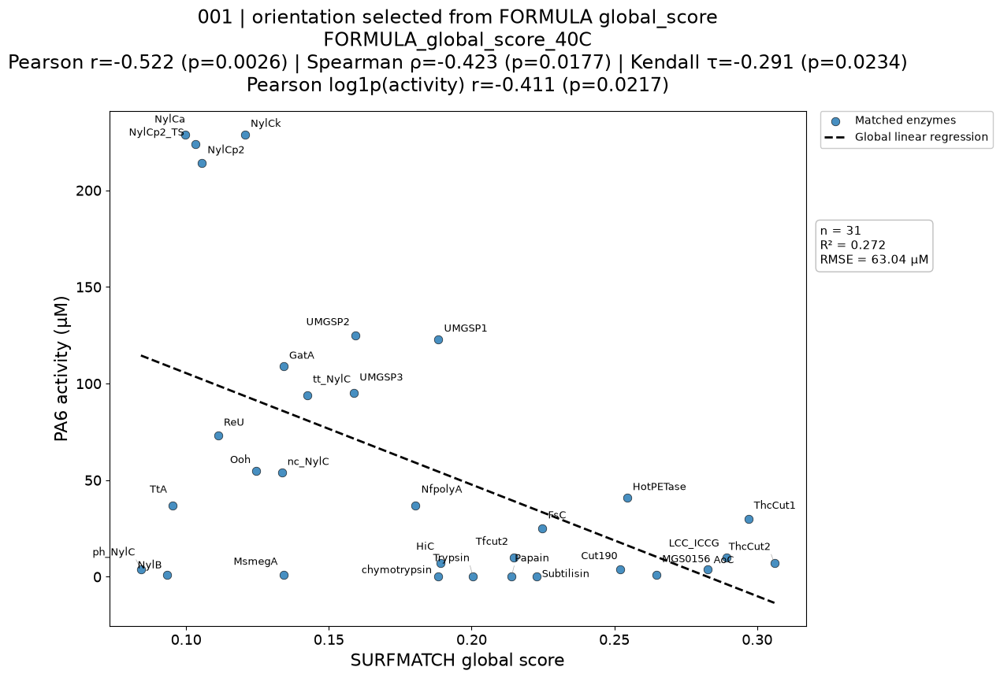

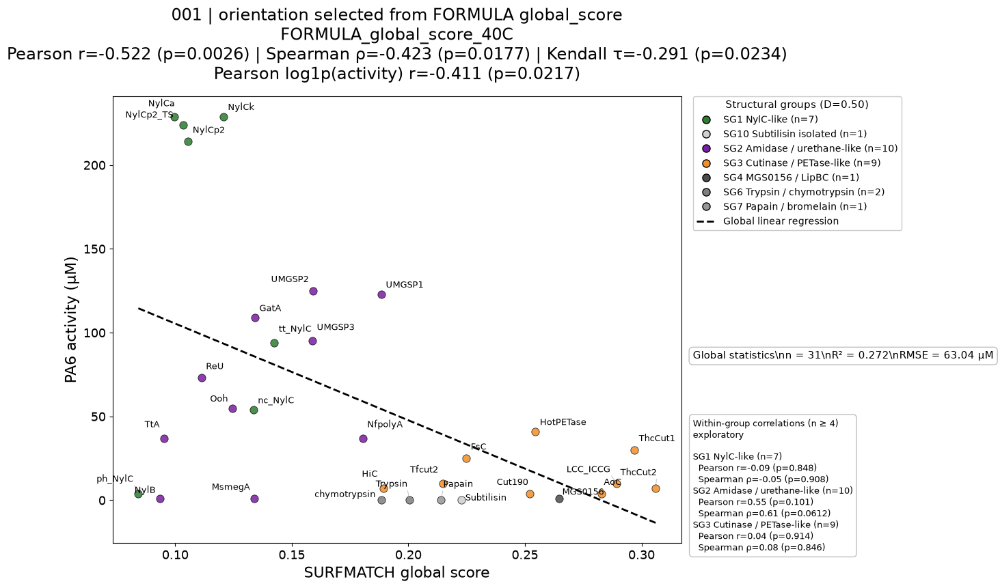

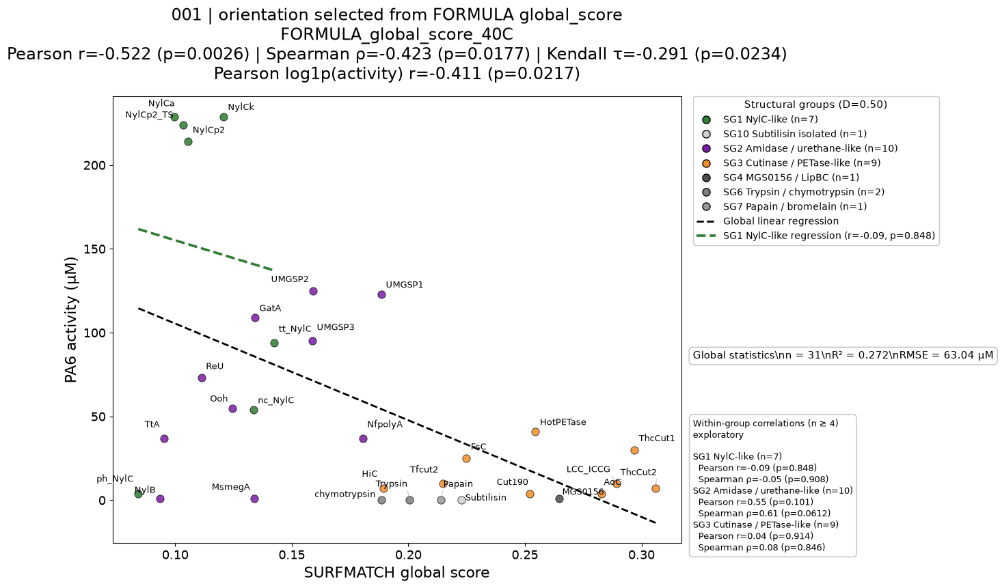

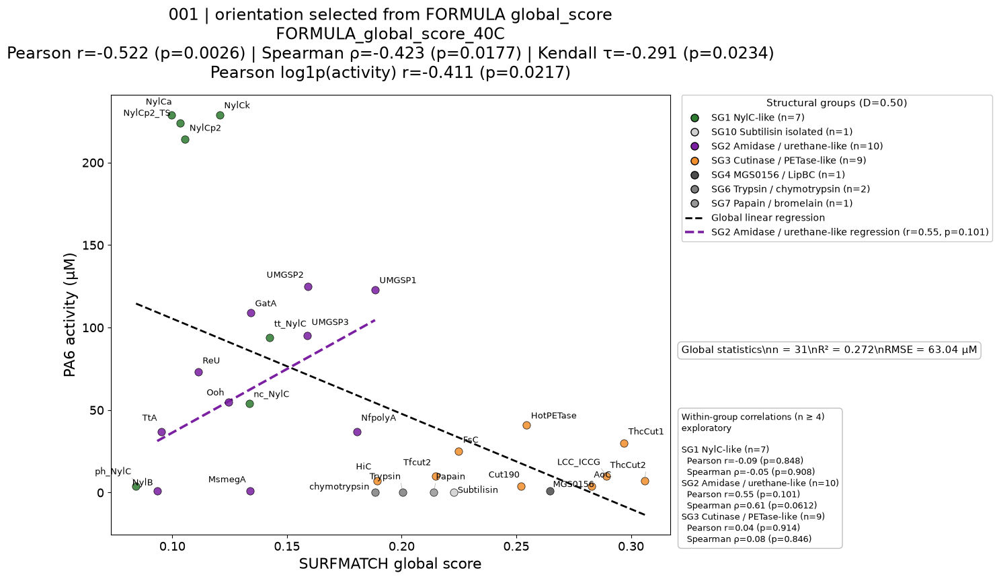

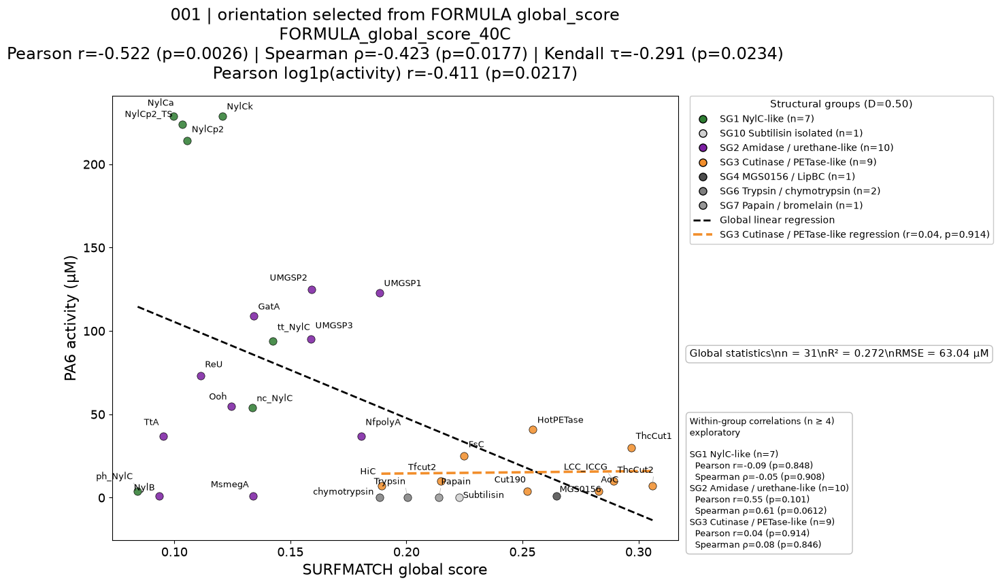

...

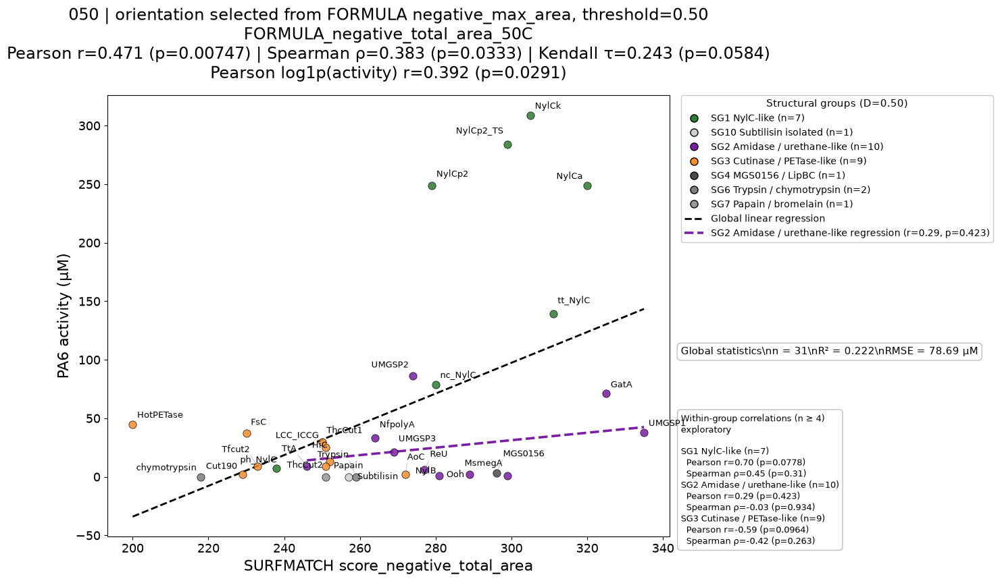

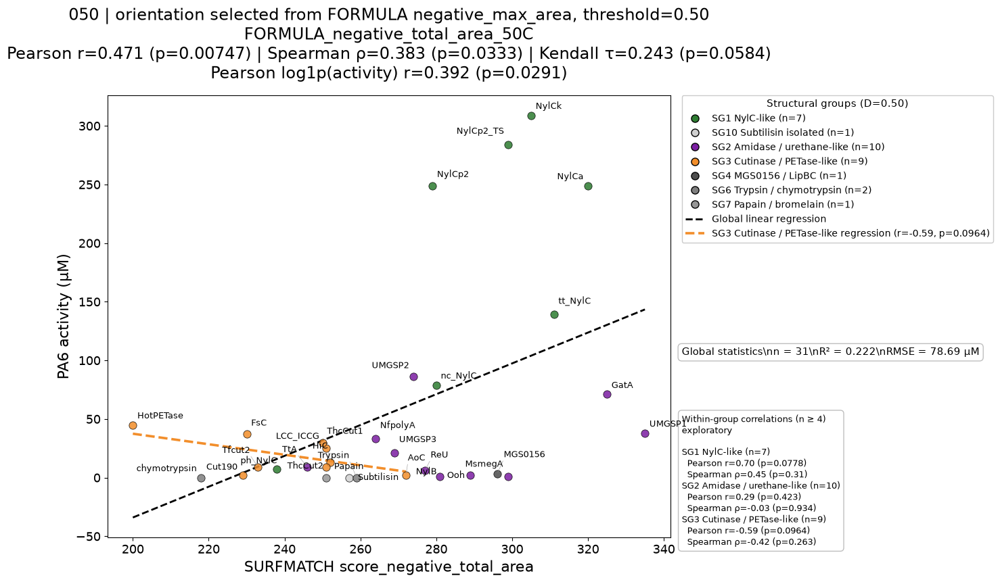

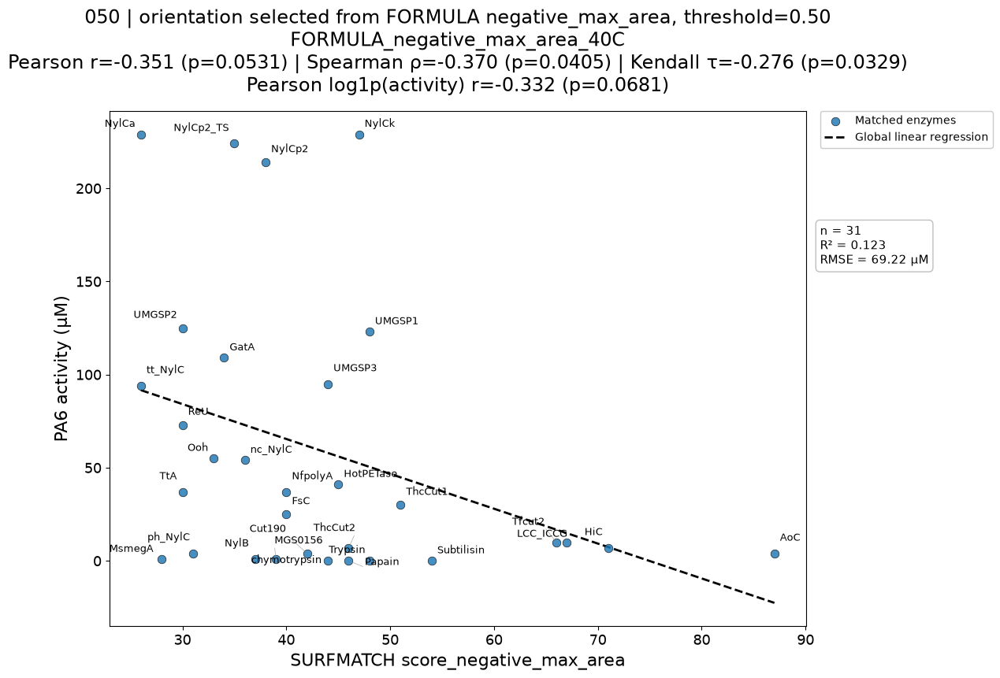

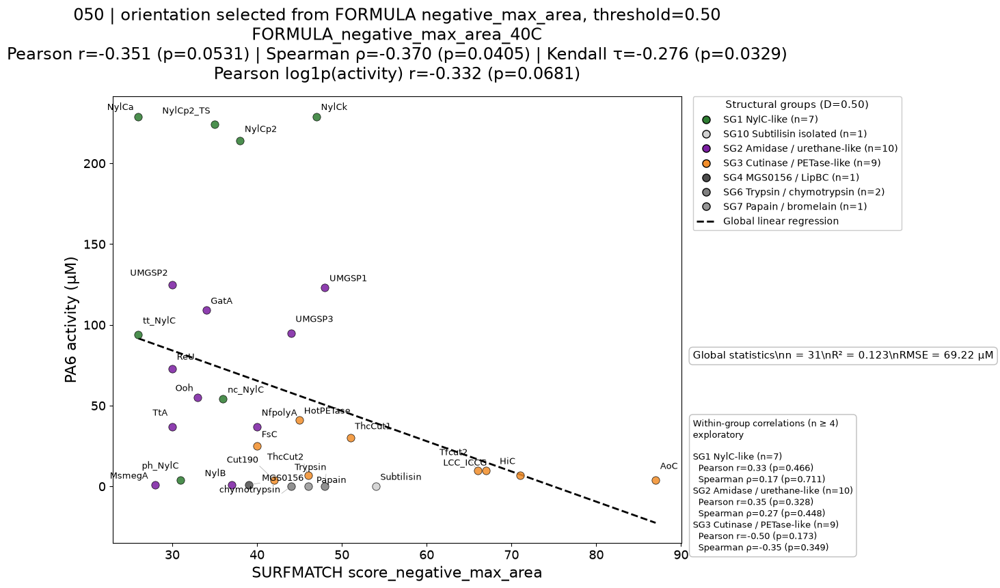

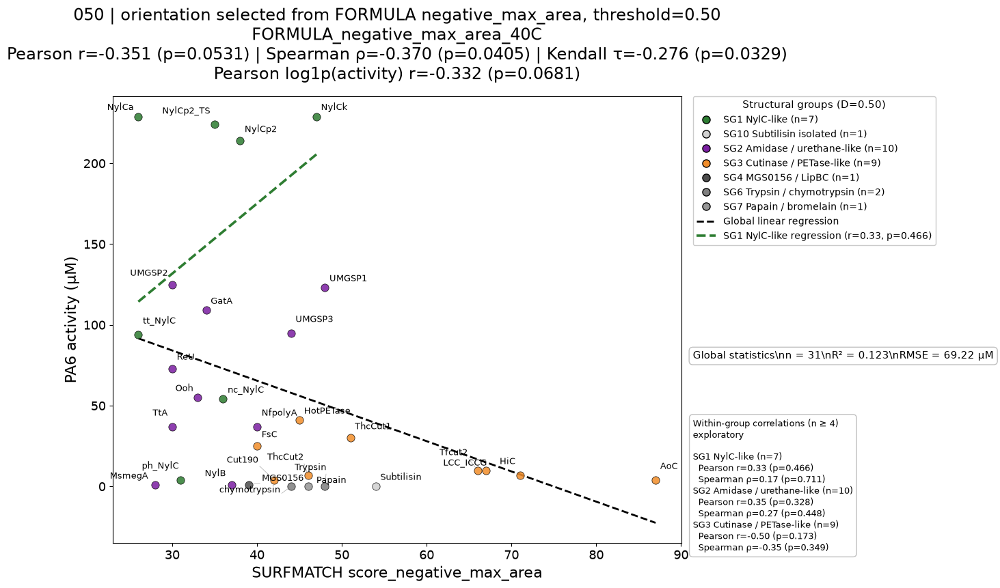

In [ ]:

all_global_results = []
all_group_results = []

for orientation_code in ORIENTATION_TABLE_CODES:

    for metric_to_plot in PLOTTED_METRICS:

        for temp in TEMPERATURES:

            # =====================================================
            # 1) STANDARD GRAPH
            # =====================================================
            standard_result = plot_standard(
                temp,
                orientation_code,
                metric_to_plot,
                show=SHOW_PLOTS,
                save=SAVE_PLOTS,
            )

            all_global_results.append(
                standard_result
            )

            # =====================================================
            # 2-5) STRUCTURAL-GROUP GRAPHS
            #
            # A. global regression only
            # B. + NylC-like / nylonase regression
            # C. + amidase / urethanase regression
            # D. + cutinase/PETase-like regression
            # =====================================================
            for structural_variant in [
                None,
                "nylonases",
                "urethanases",
                "cutinases",
            ]:
                grouped_result, group_result_df = (
                    plot_structural_groups(
                        temp,
                        orientation_code,
                        metric_to_plot,
                        group_regression=structural_variant,
                        show=SHOW_PLOTS,
                        save=SAVE_PLOTS,
                    )
                )

                all_global_results.append(
                    grouped_result
                )

                all_group_results.append(
                    group_result_df
                )


global_results_df = pd.DataFrame(
    all_global_results
)

group_results_df = pd.concat(
    all_group_results,
    ignore_index=True,
)


# ============================================================
# SAVE SUMMARY TABLES
# ============================================================
global_results_df.to_csv(
    OUTPUT_DIR
    / "correlation_summary_all_plot_variants.csv",
    index=False,
)

global_results_df.to_excel(
    OUTPUT_DIR
    / "correlation_summary_all_plot_variants.xlsx",
    index=False,
)

group_results_df.to_csv(
    OUTPUT_DIR
    / "correlation_summary_by_structural_group.csv",
    index=False,
)

group_results_df.to_excel(
    OUTPUT_DIR
    / "correlation_summary_by_structural_group.xlsx",
    index=False,
)


n_combinations = (
    len(ORIENTATION_TABLE_CODES)
    * len(PLOTTED_METRICS)
    * len(TEMPERATURES)
)

print("\nDONE")
print("Output:", OUTPUT_DIR)

print(
    "Orientation tables:",
    len(ORIENTATION_TABLE_CODES),
)

print(
    "Orientation × metric × temperature combinations:",
    n_combinations,
)

print(
    "Figures per combination: 5 "
    "(1 standard + 4 structural-group variants)"
)

print(
    "Total plots produced:",
    n_combinations * 5,
)

display(global_results_df.head())
display(group_results_df.head())



## 13. How to interpret the plot types

### Standard graph

- one colour for all matched enzymes;
- no Top-rated information;
- global Pearson, Spearman and Kendall correlations;
- global linear regression;
- legend outside the axes;
- `n`, `R²` and `RMSE` outside the axes under the legend.

### Structural-group graphs

For every orientation × metric × temperature combination, four structural-group figures are generated:

1. **global_only**  
   coloured structural groups + global regression only;

2. **nylonases**  
   same points, colours and global regression + the regression line for `SG1 NylC-like`;

3. **urethanases**  
   same points, colours and global regression + the regression line for `SG2 Amidase / urethane-like`;

4. **cutinases**  
   same points, colours and global regression + the regression line for `SG3 Cutinase / PETase-like`.

The global correlation in the title is identical across these four versions.  
Only the additional within-group regression line changes.

A within-group line is shown only when the group contains at least `MIN_GROUP_CORR_N` matched enzymes.

All plot text is black and all figure/axes backgrounds are white.


### Colour convention

The structural-group colours are fixed across every figure:

- `SG1 NylC-like` = green
- `SG2 Amidase / urethane-like` = purple
- `SG3 Cutinase / PETase-like` = orange
- smaller structural groups = grey shades

Regression lines:

- global regression = black dashed
- NylC-like regression = green dashed
- amidase / urethane-like regression = purple dashed
- cutinase / PETase-like regression = orange dashed
